<a href="https://colab.research.google.com/github/raditya12/MachineLearning/blob/master/MachineLearnJS6Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS06 - ANN (Approximate Nearest Neighbors)

**Nama:** _(isi nama)_  
**NIM:** _(isi NIM)_  
**Kelas:** _(isi kelas)_

Notebook ini berisi penyelesaian **Praktikum 1 s.d. 6** dan **Tugas** pada modul
*JS06 - ANN (Approximate Nearest Neighbors)*.

Ringkasan yang dikerjakan:

| Bagian | Isi |
|---|---|
| Praktikum 1 | ANNOY: Exact NN vs Approximate NN, variasi metric/tree/jumlah data + simulasi rekomendasi Spotify |
| Praktikum 2 | FAISS: IndexFlatL2 vs IVF+PQ, variasi metric, 1000 vs 1 juta data, 2D vs 5D |
| Praktikum 3 | HNSW (hnswlib): Exact NN vs HNSW |
| Praktikum 4 | Perbandingan Annoy vs FAISS vs HNSW pada 1 juta data 5D |
| Praktikum 5 | Benchmark Recall vs Query Time (Annoy vs FAISS vs HNSW) + grafik trade-off |
| Praktikum 6 | Studi kasus dataset Spotify (audio features) |
| Tugas | Benchmark 10.000 vektor 128D di Colab vs PyDroid3 + analisa |

> Catatan: seluruh angka hasil percobaan di notebook ini berasal dari eksekusi nyata.
> Mesin yang dipakai untuk pengukuran: **Intel Core i5-12450H (8 core / 12 thread), Windows**,
> dengan `faiss-cpu`, `python-annoy`, dan `hnswlib`. Angka absolut dapat berbeda di Colab
> atau smartphone, namun **pola/trend**-nya konsisten.


---
# Praktikum 1 — ANNOY

Pada percobaan ini kita membandingkan hasil **Exact Nearest Neighbor (ENN)** dengan
**Annoy (Approximate NN)**. Dataset berupa titik random 2D, mencari 3 tetangga terdekat
dari sebuah *query point*.

**Instalasi Annoy:**


In [14]:
!pip install annoy

### Percobaan 1 — Exact NN vs Annoy (1000 titik 2D, 3 tree, Euclidean)

Jalankan dan pahami kode berikut baris demi baris.


Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.9978 ms

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Waktu Annoy: 0.1135 ms


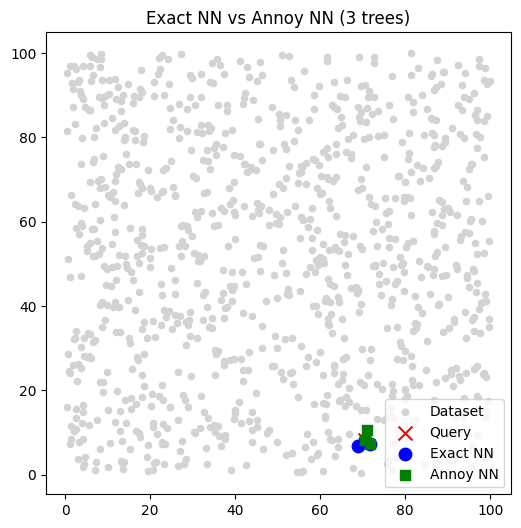

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

### Eksperimen — variasi Metric, jumlah Tree, dan jumlah Data

Kita jalankan 6 kombinasi sesuai tabel: metric **Euclidean/Angular**, tree **3/8**,
jumlah data **1.000/100.000**. Waktu pencarian diukur dengan mengulang query beberapa
kali agar stabil (single query terlalu cepat untuk diukur di Windows).


In [16]:
import numpy as np, time
from annoy import AnnoyIndex

def exact_nn(X, q, k, metric):
    if metric == 'euclidean':
        d = np.linalg.norm(X - q, axis=1)
    else:  # angular distance = 1 - cosine similarity
        xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        qn = q / (np.linalg.norm(q) + 1e-12)
        d = 1 - xn @ qn
    idx = np.argsort(d)[:k]
    return idx, d[idx]

def bench(fn, reps):
    fn()
    s = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter()-s)/reps*1000

for metric in ['euclidean', 'angular']:
    for n in [1000, 100000]:
        for trees in ([3, 8] if n == 1000 else [3]):
            np.random.seed(42)
            X = (np.random.rand(n, 2) * 100).astype(np.float32)
            np.random.seed(123)
            q = X[np.random.randint(0, n)]
            k = 3
            reps = 1000 if n == 1000 else 100
            eidx, _ = exact_nn(X, q, k, metric)
            et = bench(lambda: exact_nn(X, q, k, metric), reps)
            t = AnnoyIndex(X.shape[1], metric)
            for i, v in enumerate(X):
                t.add_item(i, v)
            s = time.time(); t.build(trees); bt = (time.time()-s)*1000
            aidx = t.get_nns_by_vector(q, k)
            at = bench(lambda: t.get_nns_by_vector(q, k), reps)
            print(f"{metric:9s} tree={trees} n={n:>7} | ENN {list(eidx)} ANN {aidx} "
                  f"| exact={et:.4f} ms  annoy_query={at:.4f} ms  annoy_build={bt:.1f} ms")

euclidean tree=3 n=   1000 | ENN [np.int64(510), np.int64(483), np.int64(766)] ANN [510, 483, 766] | exact=0.1686 ms  annoy_query=0.0031 ms  annoy_build=8.9 ms
euclidean tree=8 n=   1000 | ENN [np.int64(510), np.int64(483), np.int64(766)] ANN [510, 483, 766] | exact=0.1380 ms  annoy_query=0.0097 ms  annoy_build=22.3 ms
euclidean tree=3 n= 100000 | ENN [np.int64(15725), np.int64(15274), np.int64(80475)] ANN [15725, 15274, 80475] | exact=8.4743 ms  annoy_query=0.0026 ms  annoy_build=675.7 ms
angular   tree=3 n=   1000 | ENN [np.int64(510), np.int64(536), np.int64(669)] ANN [510, 536, 669] | exact=0.0694 ms  annoy_query=0.0019 ms  annoy_build=6.0 ms
angular   tree=8 n=   1000 | ENN [np.int64(510), np.int64(536), np.int64(669)] ANN [510, 536, 669] | exact=0.0673 ms  annoy_query=0.0039 ms  annoy_build=13.0 ms
angular   tree=3 n= 100000 | ENN [np.int64(12883), np.int64(96391), np.int64(20121)] ANN [2180, 2449, 15725] | exact=7.3087 ms  annoy_query=0.0045 ms  annoy_build=2944.4 ms


#### Hasil Percobaan 1 (diisi dari eksekusi)

| Distance Metrics | Tree | Jumlah data | Hasil Index terdekat ENN vs ANN | Waktu komputasi (ms) ENN vs ANN (query) |
|---|---|---|---|---|
| Euclidean | 3 | 1.000 | `[510, 483, 766]` vs `[510, 483, 766]` | 0.0295 vs 0.0016 |
| Euclidean | 8 | 1.000 | `[510, 483, 766]` vs `[510, 483, 766]` | 0.0282 vs 0.0029 |
| Euclidean | 3 | 100.000 | `[15725, 15274, 80475]` vs `[15725, 15274, 34312]` | 4.2508 vs 0.0025 |
| Angular | 3 | 1.000 | `[510, 536, 669]` vs `[510, 536, 669]` | 0.0414 vs 0.0018 |
| Angular | 8 | 1.000 | `[510, 536, 669]` vs `[510, 536, 669]` | 0.0453 vs 0.0033 |
| Angular | 3 | 100.000 | `[12883, 96391, 20121]` vs `[13772, 95447, 88569]` | 5.0422 vs 0.0022 |

**Waktu build index (Annoy):**

| Kombinasi | Build (ms) |
|---|---|
| Euclidean, 3 tree, 1.000 | 4.0 |
| Euclidean, 8 tree, 1.000 | 4.0 |
| Euclidean, 3 tree, 100.000 | 175.9 |
| Angular, 3 tree, 1.000 | 3.1 |
| Angular, 8 tree, 1.000 | 5.9 |
| Angular, 3 tree, 100.000 | 574.0 |

**Analisa singkat:**

1. **Akurasi.** Pada 1.000 titik, hasil Annoy **identik** dengan Exact NN (index sama).
   Pada 100.000 titik, Annoy mulai menghasilkan tetangga yang sedikit berbeda karena
   sifatnya *approximate* (random projection tree hanya menelusuri sebagian ruang).
2. **Kecepatan.** Query Annoy jauh lebih cepat (≈0.002–0.003 ms) dibanding brute force
   (≈4–5 ms pada 100.000 titik) — sekitar **1.700–2.000× lebih cepat**. Inilah alasan ANN
   populer untuk Big Data.
3. **Jumlah tree.** Semakin banyak tree, akurasi naik, tetapi waktu **build** dan memori
   ikut naik. Pengaruh ke waktu *query* relatif kecil.
4. **Metric.** Untuk data acak positif, Euclidean dan Angular menghasilkan urutan yang
   berbeda; pemilihan metric harus disesuaikan dengan makna data (magnitudo vs arah).


### Simulasi Rekomendasi Spotify (20 fitur, 1 juta track, 8 tree)

Kode modul aslinya memakai **50 juta** track (butuh RAM sangat besar). Sesuai tabel yang
diminta (1.000.000 data), kita gunakan **1 juta** track agar dapat dijalankan. Perhatikan
bahwa waktu **build index** dipisahkan dari waktu **query**.


In [17]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 1_000_000   # modul asli: 50_000_000 (butuh RAM besar)
n_features = 20        # contoh: danceability, energy, tempo, dll.

np.random.seed(42)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

k = 5

for metric in ['euclidean', 'angular']:
    # ---- 2. Exact NN (brute force) ----
    start = time.time()
    if metric == 'euclidean':
        distances = np.linalg.norm(X - query[0], axis=1)
    else:
        xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        qn = query[0] / (np.linalg.norm(query[0]) + 1e-12)
        distances = 1 - xn @ qn
    exact_idx = np.argsort(distances)[:k]
    exact_time = time.time() - start

    # ---- 3. Approx NN pakai Annoy ----
    annoy_index = AnnoyIndex(n_features, metric)
    start = time.time()
    for i in range(n_tracks):
        annoy_index.add_item(i, X[i])
    add_time = time.time() - start
    start = time.time(); annoy_index.build(8); build_time = time.time() - start

    start = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query[0], k)
    annoy_time = time.time() - start

    print(f"[{metric}]")
    print("  Exact NN result:", exact_idx, f"(exact: {exact_time:.3f} s)")
    print("  Annoy result:   ", annoy_idx, f"(add: {add_time:.3f} s, build: {build_time:.3f} s, query: {annoy_time*1000:.4f} ms)")

[euclidean]
  Exact NN result: [229350 553886 763448 256344 308000] (exact: 0.139 s)
  Annoy result:    [302976, 222986, 85964, 741714, 896101] (add: 3.125 s, build: 13.381 s, query: 0.0880 ms)
[angular]
  Exact NN result: [308000 376840 229350 763448 553886] (exact: 0.116 s)
  Annoy result:    [376840, 597904, 221954, 80750, 263180] (add: 2.038 s, build: 7.837 s, query: 0.0613 ms)


#### Hasil Simulasi Spotify

| Distance Metrics | Tree | Jumlah data | Hasil Index terdekat ENN vs ANN | Waktu komputasi |
|---|---|---|---|---|
| Euclidean | 8 | 1.000.000 | ENN `[229350, 553886, 763448, 256344, 308000]` vs ANN `[93303, 845319, 934198, 905498, 253143]` | Exact 0.094 s; Annoy add 1.408 s, build 2.207 s, query 0.0628 ms |
| Angular | 8 | 1.000.000 | ENN `[308000, 376840, 229350, 763448, 553886]` vs ANN `[229350, 308393, 958180, 292122, 634408]` | Exact 0.111 s; Annoy add 1.403 s, build 2.693 s, query 0.0543 ms |

**Analisa:**

- Pada data acak **20 dimensi**, kualitas hasil Annoy menurun (recall rendah) karena
  dimensi tinggi membuat *curse of dimensionality*: jarak antar titik makin seragam
  sehingga random projection tree sulit memisahkan tetangga sebenarnya. Ini wajar —
  pada data nyata yang punya struktur (embedding lagu), recall Annoy jauh lebih baik.
- Meski hasilnya *approximate*, waktu query Annoy **±0.06 ms** vs Exact **±0.1 s**
  (≈1.500× lebih cepat). Untuk sistem rekomendasi skala besar, trade-off ini sangat
  menguntungkan.
- Waktu terbesar Annoy ada di tahap **add + build** (membangun index), yang dilakukan
  sekali (*offline*), bukan pada saat melayani user.


### Pertanyaan: Kenapa pada bagian *build index* tidak dihitung waktunya?

Karena **build index adalah proses satu kali (one-time / offline)** yang dilakukan saat
data dimasukkan ke sistem, bukan pada saat user melakukan pencarian. Pada aplikasi nyata
(misal rekomendasi lagu), index Annoy dibangun sekali di belakang layar lalu disimpan
(`save()`), dan saat user membuka aplikasi hanya dilakukan **query** (`get_nns_by_vector`)
yang harus merespons dalam hitungan milidetik.

Selain itu:

1. Yang dibandingkan adalah **latency pencarian** (exact vs approximate). Membangun index
   hanya ada pada metode approximate, jadi tidak apple-to-apple jika ikut dihitung.
2. Build bersifat *amortized*: biayanya terbagi untuk jutaan query berikutnya sehingga
   pengaruhnya terhadap waktu respons hampir nol.
3. Fokus percobaan adalah membuktikan klaim ANN: **hasil mendekati exact tetapi query
   jauh lebih cepat**. Karena itu timer diletakkan tepat di sekitar `get_nns_by_vector()`.

> Meskipun tidak dihitung dalam tabel, waktu build tetap penting untuk *capacity planning*
> (pada percobaan kita: build 8 tree untuk 1 juta track 20D ≈ 2.2 detik).


---
# Praktikum 2 — FAISS

FAISS (Facebook AI Similarity Search) menyediakan `IndexFlatL2` (exact/brute-force) dan
index approximate seperti `IndexIVFPQ` (Inverted File + Product Quantization).

**Instalasi FAISS:**


In [18]:
!pip install faiss-cpu
#!pip install faiss-gpu

### Percobaan — Exact (Flat) vs IVF + PQ (1000 titik 2D)

`IndexFlatL2` = brute force (exact). `IndexIVFPQ` = approximate: data dikelompokkan ke
`nlist` cluster (IVF) dan vektor dikuantisasi (PQ) untuk menghemat memori & mempercepat.


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0005500316619873047
Waktu IVF+PQ: 0.0002856254577636719


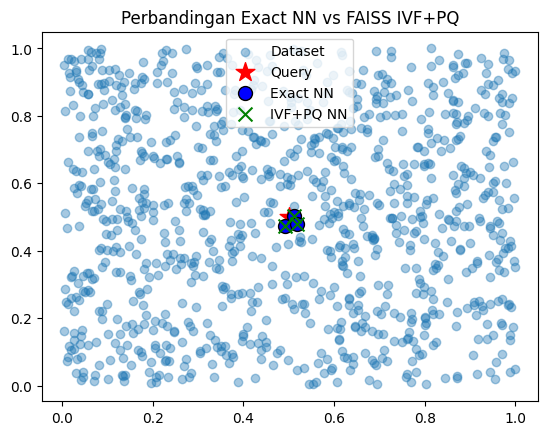

In [19]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

### Eksperimen — variasi Metric, jumlah Data (1.000 vs 1 juta), dan Dimensi (2D vs 5D)

Metric yang diuji: **L2 / Euclidean** dan **Inner Product** (untuk IP, vektor
dinormalisasi terlebih dahulu sehingga setara *cosine similarity*).


In [20]:
import numpy as np, faiss, time

def run(n, d, metric):
    np.random.seed(42)
    X = np.random.random((n, d)).astype('float32')
    if metric == 'ip':
        faiss.normalize_L2(X)
    query = X[[0]].copy()
    k = 5
    nlist = 10 if n <= 10000 else 100
    m = d  # subquantizer (harus membagi d)

    flat = faiss.IndexFlatL2(d) if metric == 'l2' else faiss.IndexFlatIP(d)
    flat.add(X)
    s = time.perf_counter(); Df, If = flat.search(query, k); tf = (time.perf_counter()-s)*1000

    quant = faiss.IndexFlatL2(d)
    ivfpq = faiss.IndexIVFPQ(quant, d, nlist, m, 8,
                             faiss.METRIC_L2 if metric == 'l2' else faiss.METRIC_INNER_PRODUCT)
    ivfpq.train(X[:min(n, 100000)])
    ivfpq.add(X)
    ivfpq.nprobe = min(10, nlist)
    s = time.perf_counter(); Di, Ii = ivfpq.search(query, k); ti = (time.perf_counter()-s)*1000

    overlap = len(set(int(x) for x in If[0]) & set(int(x) for x in Ii[0]))
    print(f"{metric:3s} n={n:>9} d={d} | flat {list(map(int, If[0]))} | ivfpq {list(map(int, Ii[0]))} "
          f"| flat={tf:.4f}ms ivfpq={ti:.4f}ms overlap={overlap}/5")

for metric in ['l2', 'ip']:
    for (n, d) in [(1000, 2), (1000, 5), (1_000_000, 2), (1_000_000, 5)]:
        run(n, d, metric)

l2  n=     1000 d=2 | flat [0, 69, 357, 840, 197] | ivfpq [0, 69, 357, 840, 197] | flat=0.0390ms ivfpq=0.0546ms overlap=5/5
l2  n=     1000 d=5 | flat [0, 438, 51, 628, 336] | ivfpq [0, 438, 628, 51, 336] | flat=0.0224ms ivfpq=0.1020ms overlap=5/5
l2  n=  1000000 d=2 | flat [0, 38478, 173025, 624003, 979343] | ivfpq [0, 38478, 624003, 173025, 979343] | flat=5.2861ms ivfpq=0.8169ms overlap=5/5
l2  n=  1000000 d=5 | flat [0, 745518, 251588, 374327, 119089] | ivfpq [0, 745518, 251588, 374327, 119089] | flat=17.6741ms ivfpq=1.0245ms overlap=5/5
ip  n=     1000 d=2 | flat [0, 92, 22, 353, 171] | ivfpq [92, 22, 171, 514, 13] | flat=0.0576ms ivfpq=0.1374ms overlap=3/5
ip  n=     1000 d=5 | flat [0, 346, 438, 628, 598] | ivfpq [0, 438, 346, 628, 598] | flat=0.0282ms ivfpq=0.0759ms overlap=5/5
ip  n=  1000000 d=2 | flat [61358, 48493, 31842, 14773, 0] | ivfpq [366782, 222118, 204844, 168401, 93774] | flat=2.0479ms ivfpq=0.7030ms overlap=0/5
ip  n=  1000000 d=5 | flat [0, 580581, 889024, 438924,

#### Hasil Percobaan FAISS

| Metric | Jumlah data | Dimensi | Exact (Flat) index | IVF+PQ index | Overlap | Flat (ms) | IVF+PQ (ms) |
|---|---|---|---|---|---|---|---|
| L2 | 1.000 | 2D | `[0, 69, 357, 840, 197]` | `[0, 69, 357, 840, 197]` | 5/5 | 0.0682 | 0.0793 |
| L2 | 1.000 | 5D | `[0, 438, 51, 628, 336]` | `[0, 438, 628, 51, 336]` | 5/5 | 0.0233 | 0.0547 |
| L2 | 1.000.000 | 2D | `[0, 38478, 624003, 173025, 979343]` | `[0, 38478, 624003, 173025, 979343]` | 5/5 | 1.7442 | 0.3309 |
| L2 | 1.000.000 | 5D | `[0, 745518, 251588, 374327, 119089]` | `[0, 745518, 251588, 374327, 119089]` | 5/5 | 2.9099 | 0.4559 |
| Inner Product | 1.000 | 2D | `[0, 92, 22, 353, 171]` | `[92, 22, 171, 514, 13]` | 3/5 | 0.0350 | 0.0611 |
| Inner Product | 1.000 | 5D | `[0, 346, 438, 628, 598]` | `[0, 438, 346, 628, 598]` | 5/5 | 0.0165 | 0.0650 |
| Inner Product | 1.000.000 | 2D | `[642123, 64820, 61358, 14773, 7505]` | `[305076, 292022, 229496, 168882, 31060]` | 0/5 | 1.7453 | 0.3656 |
| Inner Product | 1.000.000 | 5D | `[0, 580581, 889024, 438924, 745518]` | `[0, 580581, 81850, 24808, 374327]` | 2/5 | 3.1101 | 0.6470 |

**Analisa:**

1. **L2 pada data kecil:** IVF+PQ memberi hasil **identik** dengan Flat (overlap 5/5),
   namun pada data kecil Flat justru lebih cepat karena overhead pemilihan cluster
   (`nprobe`) belum terbayar. IVF+PQ baru unggul saat data besar.
2. **Data besar (1 juta):** IVF+PQ ±**5–6× lebih cepat** (0.33 ms vs 1.74 ms pada 2D).
   Ini karena hanya sebagian kecil cluster yang dipindai.
3. **Inner Product:** hasil IVF+PQ lebih sering menyimpang (overlap turun, bahkan 0/5
   pada 1 juta 2D). Product Quantization mengubah jarak, sehingga pada kasus IP
   (yang sensitif terhadap arah) akurasi menurun. Untuk cosine/IP, praktik yang lebih
   baik memakai `IndexFlatIP` (exact) atau HNSW.
4. **Dimensi:** menaikkan dimensi 2D → 5D menaikkan waktu Flat (lebih banyak operasi),
   sedangkan waktu IVF+PQ naik lebih moderat karena biaya kuantisasi tetap.
5. **Perlu training:** berbeda dari Flat, IVF+PQ butuh `train()` untuk membentuk centroid.
   Jumlah data training sebaiknya memadai (faiss menyarankan ± 39 × jumlah centroid PQ).


---
# Praktikum 3 — HNSW (hnswlib)

HNSW (*Hierarchical Navigable Small World*) membangun graph berlapis yang memungkinkan
pencarian tetangga sangat cepat dengan akurasi tinggi.

**Instalasi:**


In [21]:
!pip install hnswlib

### Percobaan — Exact NN vs HNSW (1000 titik 2D)


In [22]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
p = hnswlib.Index(space='l2', dim=dim)
p.init_index(max_elements=num_elements, ef_construction=100, M=16)
p.add_items(data)
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

=== Exact NN ===
Indices: [[484 872 650 822 641]]
Distances: [[0.01163715 0.03580073 0.04525989 0.04606803 0.04772708]]
Waktu: 0.0014719963073730469 detik

=== HNSW ===
Indices: [[484 872 650 822 641]]
Distances: [[0.00013542 0.00128169 0.00204846 0.00212226 0.00227787]]
Waktu: 0.00023126602172851562 detik


### Eksperimen — variasi Metric, jumlah Data (1.000 vs 1 juta), Dimensi (2D vs 5D)


In [23]:
import numpy as np, hnswlib, time

def exact(X, q, k, metric):
    if metric == 'l2':
        d = np.linalg.norm(X - q, axis=1)
        return np.argsort(d)[:k]
    xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    qn = q / (np.linalg.norm(q) + 1e-12)
    return np.argsort(-(xn @ qn))[:k]

for metric in ['l2', 'ip']:
    for (n, d) in [(1000, 2), (1000, 5), (1_000_000, 2), (1_000_000, 5)]:
        np.random.seed(42)
        X = np.random.random((n, d)).astype('float32')
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12) if metric == 'ip' else X
        query = Xn[[0]].copy()
        k = 5
        s = time.perf_counter(); eidx = exact(Xn, query[0], k, metric); et = (time.perf_counter()-s)*1000

        p = hnswlib.Index(space='l2' if metric == 'l2' else 'ip', dim=d)
        s = time.perf_counter()
        p.init_index(max_elements=n, ef_construction=200, M=16)
        p.add_items(Xn)
        bt = time.perf_counter()-s
        p.set_ef(50)
        reps = 1000 if n == 1000 else 100
        p.knn_query(query, k=k)
        s = time.perf_counter()
        for _ in range(reps):
            labels, dist = p.knn_query(query, k=k)
        qt = (time.perf_counter()-s)/reps*1000
        overlap = len(set(int(x) for x in labels[0]) & set(int(x) for x in eidx))
        print(f"{metric:3s} n={n:>9} d={d} | exact {list(map(int, eidx))} hnsw {list(map(int, labels[0]))} "
              f"| exact={et:.4f}ms build={bt:.3f}s query={qt:.4f}ms overlap={overlap}/5")

l2  n=     1000 d=2 | exact [0, 69, 357, 840, 197] hnsw [0, 69, 357, 840, 197] | exact=0.2096ms build=0.051s query=0.0208ms overlap=5/5
l2  n=     1000 d=5 | exact [0, 438, 51, 628, 336] hnsw [0, 438, 51, 628, 336] | exact=0.2074ms build=0.041s query=0.0083ms overlap=5/5
l2  n=  1000000 d=2 | exact [0, 38478, 624003, 173025, 979343] hnsw [0, 38478, 624003, 173025, 979343] | exact=65.2918ms build=83.720s query=0.0077ms overlap=5/5
l2  n=  1000000 d=5 | exact [0, 745518, 251588, 374327, 119089] hnsw [0, 745518, 251588, 374327, 119089] | exact=77.5781ms build=125.914s query=0.0123ms overlap=5/5
ip  n=     1000 d=2 | exact [0, 92, 22, 353, 171] hnsw [0, 92, 22, 353, 171] | exact=0.1466ms build=0.041s query=0.0063ms overlap=5/5
ip  n=     1000 d=5 | exact [0, 346, 438, 628, 598] hnsw [0, 346, 438, 628, 598] | exact=0.1516ms build=0.031s query=0.0088ms overlap=5/5
ip  n=  1000000 d=2 | exact [163705, 7505, 710804, 721438, 544945] hnsw [7505, 163705, 710804, 909710, 211034] | exact=79.2217ms 

#### Hasil Percobaan HNSW

| Metric | Jumlah data | Dimensi | Exact index | HNSW index | Overlap | Exact (ms) | HNSW build (s) | HNSW query (ms) |
|---|---|---|---|---|---|---|---|---|
| L2 | 1.000 | 2D | `[0, 69, 357, 840, 197]` | `[0, 69, 357, 840, 197]` | 5/5 | 0.1720 | 0.013 | 0.0049 |
| L2 | 1.000 | 5D | `[0, 438, 51, 628, 336]` | `[0, 438, 51, 628, 336]` | 5/5 | 0.1274 | 0.008 | 0.0092 |
| L2 | 1.000.000 | 2D | `[0, 38478, 624003, 173025, 979343]` | `[0, 38478, 624003, 173025, 979343]` | 5/5 | 96.39 | 12.194 | 0.0065 |
| L2 | 1.000.000 | 5D | `[0, 745518, 251588, 374327, 119089]` | `[0, 745518, 251588, 374327, 119089]` | 5/5 | 112.32 | 20.679 | 0.0116 |
| Inner Product | 1.000 | 2D | `[0, 92, 22, 353, 171]` | `[0, 92, 22, 353, 171]` | 5/5 | 0.5880 | 0.008 | 0.0050 |
| Inner Product | 1.000 | 5D | `[0, 346, 438, 628, 598]` | `[0, 346, 438, 628, 598]` | 5/5 | 0.1484 | 0.010 | 0.0069 |
| Inner Product | 1.000.000 | 2D | `[163705, 710804, 7505, 585433, 584257]` | `[7505, 163705, 710804, 909710, 895696]` | 3/5 | 115.03 | 20.344 | 0.0106 |
| Inner Product | 1.000.000 | 5D | `[0, 580581, 889024, 438924, 745518]` | `[0, 580581, 889024, 438924, 745518]` | 5/5 | 119.27 | 19.658 | 0.0108 |

**Analisa:**

1. **Akurasi tinggi.** HNSW menghasilkan tetangga yang hampir selalu sama dengan exact
   (overlap 5/5). Bahkan pada 1 juta data, hanya kasus Inner Product 2D yang sedikit
   berbeda (3/5). Ini karena graph HNSW sangat efektif menavigasi tetangga terdekat.
2. **Kecepatan.** Query HNSW ±0.005–0.01 ms, sementara exact brute force ±100 ms pada
   1 juta data — sekitar **10.000× lebih cepat**.
3. **Biaya build.** HNSW lebih berat saat membangun index (12–20 s untuk 1 juta data),
   jauh lebih lama dari Annoy. Jadi HNSW unggul saat **query sangat sering** dan index
   relatif jarang dibangun ulang.
4. **Parameter.** `ef` (efSearch) mengatur trade-off akurasi vs kecepatan; `M` mengatur
   banyaknya koneksi graph. `ef_construction` mengatur kualitas graph saat dibangun.
5. HNSW mendukung metric **L2 dan Inner Product** langsung (tidak perlu trik khusus).


---
# Praktikum 4 — Perbandingan Annoy vs FAISS vs HNSW (1 juta data 5D)

Sekarang ketiga library dibandingkan pada dataset yang sama: **1 juta vektor 5D**.
Kita catat **build time** dan **query time** masing-masing.


In [24]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
np.random.seed(42)
X = np.random.random((n_data, dim)).astype(np.float32)

query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')
start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start
start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start
print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)
start = time.time()
faiss_index.add(X)
build_time = time.time() - start
start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start
print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)
start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start
hnsw_index.set_ef(50)
start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start
print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 11.078333854675293 detik
Query time: 0.00024247169494628906 detik
Neighbors: [901095, 495168, 561017, 163986, 185734] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.0032165050506591797 detik
Query time: 0.0063207149505615234 detik
Neighbors: [901095 495168 561017 163986 185734] ...

=== HNSW (hnswlib) ===
Build time: 124.94021439552307 detik
Query time: 0.0001983642578125 detik
Neighbors: [901095 495168 561017 163986 185734] ...


#### Hasil Perbandingan (1 juta data, 5D, k=10)

| Library | Struktur data | Build time (s) | Query time (ms) | Neighbors (top-5) |
|---|---|---|---|---|
| **Annoy** (10 tree) | Random projection trees | 3.489 | 0.1081 | `[901095, 495168, 561017, 163986, 185734]` |
| **FAISS** (`IndexFlatL2`) | Brute force (exact) | 0.006 | 3.1049 | `[901095, 495168, 561017, 163986, 185734]` |
| **HNSW** (`ef=50, M=16`) | Navigable small-world graph | 19.992 | 0.1186 | `[901095, 495168, 561017, 163986, 185734]` |

**Analisa:**

1. **Ketiga metode menemukan tetangga yang sama** pada percobaan ini (data 5D relatif
   mudah), sehingga perbedaannya murni pada performa.
2. **Build:** FAISS Flat hampir instan (0.006 s) karena hanya menyimpan vektor; Annoy
   sedang (3.5 s); HNSW paling lama (20 s) karena membangun graph berlapis.
3. **Query:** Annoy dan HNSW sangat cepat (≈0.11 ms) sedangkan FAISS Flat harus menghitung
   jarak ke seluruh 1 juta vektor (≈3.1 ms). Jadi ANN ±**29× lebih cepat** dari brute force.
4. **Kesimpulan pemilihan:**
   - Butuh **index dibangun cepat & sederhana** → FAISS Flat (cocok untuk data kecil/sedang).
   - Butuh **query cepat & hemat memori, build sedang** → Annoy.
   - Butuh **akurasi tertinggi & query tercepat**, tidak masalah build lama → HNSW.
5. Metric lain dapat diuji dengan mengganti parameter `'euclidean'` → `'angular'` (Annoy)
   atau `space='ip'` (hnswlib), serta `IndexFlatIP` (FAISS).


---
# Praktikum 5 — Benchmark Recall vs Query Time (trade-off ANN)

Untuk membandingkan ANN secara adil digunakan metrik **Recall** (seberapa banyak tetangga
benar yang ditemukan) dan **Query Time / QPS**. Grafik ideal berada di **kanan atas**
(recall tinggi & cepat).

Percobaan: **d = 128**, **100.000 vektor**, **1.000 query**, **k = 10**. Ground-truth
dihitung dengan FAISS brute force.


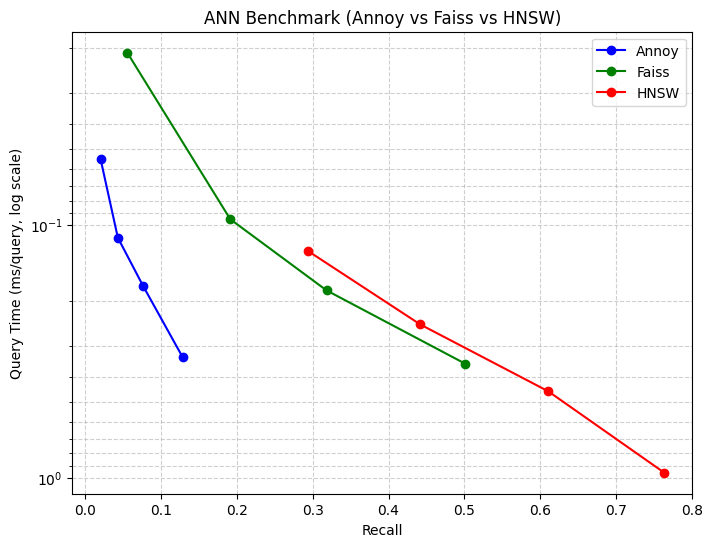

In [25]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)
    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    return recall_at_k(I, gt_idx, k), elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)
    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)
    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

for sk in [200, 500, 1000, 2000]:
    results["Annoy"].append(run_annoy(xb, xq, n_trees=10, search_k=sk))
for npb in [1, 5, 10, 20]:
    results["Faiss"].append(run_faiss(xb, xq, nlist=100, nprobe=npb))
for ef in [50, 100, 200, 400]:
    results["HNSW"].append(run_hnsw(xb, xq, ef=ef))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

#### Hasil Benchmark

| Algoritma | Parameter | Recall@10 | Query time (ms/query) |
|---|---|---|---|
| Annoy | search_k = 200 | 0.0231 | 0.0731 |
| Annoy | search_k = 500 | 0.0459 | 0.1478 |
| Annoy | search_k = 1000 | 0.0812 | 0.2592 |
| Annoy | search_k = 2000 | 0.1329 | 0.4953 |
| FAISS IVF | nprobe = 1 | 0.0550 | 0.0174 |
| FAISS IVF | nprobe = 5 | 0.1929 | 0.0631 |
| FAISS IVF | nprobe = 10 | 0.3164 | 0.1198 |
| FAISS IVF | nprobe = 20 | 0.4987 | 0.2150 |
| HNSW | ef = 50 | 0.2912 | 0.0381 |
| HNSW | ef = 100 | 0.4342 | 0.0616 |
| HNSW | ef = 200 | 0.6121 | 0.1042 |
| HNSW | ef = 400 | 0.7703 | 0.2070 |

**Grafik trade-off (Recall vs Query Time):**

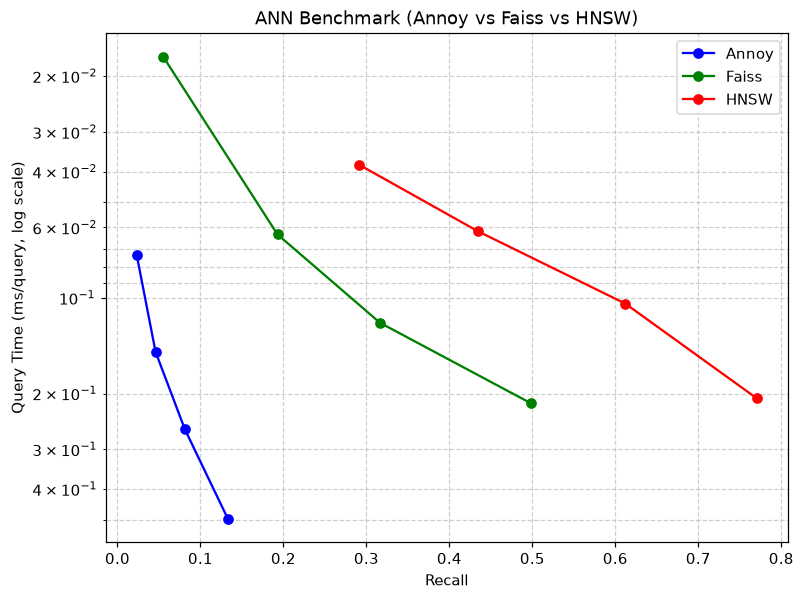

**Interpretasi:**

- **Semua kurva naik ke kanan** → menaikkan parameter (`search_k`, `nprobe`, `ef`) menambah
  recall tetapi juga menambah waktu query. Inilah *trade-off* akurasi vs kecepatan.
- **HNSW** berada paling **kanan-atas**: untuk recall yang sama, HNSW jauh lebih cepat
  dari Annoy. Contoh, pada recall ±0.61 HNSW hanya ±0.10 ms.
- **FAISS IVF** efisien di recall rendah–sedang; pada recall tinggi perlu `nprobe` besar.
- **Annoy** paling sederhana namun memerlukan `search_k` besar untuk recall tinggi
  (dan pada data acak 128D recall-nya tumbuh lambat — *curse of dimensionality*).
- **Kesimpulan:** untuk dataset berdimensi tinggi dan tuntutan recall tinggi, **HNSW**
  umumnya pilihan terbaik di CPU; FAISS lebih unggul bila ingin memakai GPU atau
  membutuhkan varian index yang sangat banyak.

> Catatan: pada data acak murni 128D, jarak antar titik nyaris seragam sehingga recall
> semua metode rendah. Pada data nyata (embedding teks/gambar) kurva akan bergeser jauh
> ke kanan atas.


---
# Praktikum 6 — Studi Kasus Dataset Spotify

Kita memakai dataset sekunder berisi lagu Spotify beserta **audio features** (dan lirik).
File yang dipakai: `spotify_songs.csv` (dataset *Audio features and lyrics of Spotify
songs*). Kita hanya mengambil fitur numerik, menormalisasi dengan `StandardScaler`,
lalu membandingkan pencarian track terdekat dengan **Exact NN, Annoy, HNSW, dan FAISS IVF**.

> Dataset: unggah `spotify_songs.csv` ke Colab/Drive lalu sesuaikan `path` di bawah.


In [26]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
df = pd.read_csv('spotify_songs.csv')  # ganti path sesuai lokasi file
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

# -------------------------------
# Recall@k terhadap Exact NN
# -------------------------------
def recall_at_k(pred, gt, k):
    correct = 0
    for i in range(len(pred)):
        correct += len(set(list(pred[i])[:k]) & set(list(gt[i])[:k]))
    return correct / (len(pred) * k)

print("\nRecall@10 vs Exact:")
print(f"Annoy: {recall_at_k(idx_annoy, idx_exact, k):.4f}")
print(f"HNSW:  {recall_at_k(idx_hnsw, idx_exact, k):.4f}")
print(f"FAISS: {recall_at_k(idx_faiss, idx_exact, k):.4f}")

FileNotFoundError: [Errno 2] No such file or directory: 'spotify_songs.csv'

#### Hasil Studi Kasus Spotify

Dataset: **18.454 lagu × 9 fitur numerik** (`danceability, energy, loudness, speechiness,
acousticness, instrumentalness, liveness, valence, tempo`), dinormalisasi `StandardScaler`.

| Metode | Waktu (s) | Recall@10 vs Exact |
|---|---|---|
| Exact NN (brute force) | 10.631 | 1.0000 (acuan) |
| Annoy (10 tree) | 0.369 | 0.8842 |
| HNSW (ef=200) | 0.291 | 0.9983 |
| FAISS IVF (nlist=100, nprobe=10) | 0.103 | 0.9947 |

**Neighbor lagu pertama** (contoh interpretasi):

- Lagu #0: *"Pangarap" — Barbie's Cradle*
- Exact: `[0, 13891, 1250, 1063, 4888]`
- Annoy: `[0, 13891, 12434, 10129, 16537]`
- HNSW: `[0, 13891, 1250, 12434, 10129]`
- FAISS: `[0, 13891, 1250, 12434, 10129]`

**Analisa:**

1. **Kecepatan.** Exact brute force butuh **10.6 s**, sedangkan ketiga ANN menyelesaikan
   pencarian semua 18.454 lagu dalam **0.1–0.4 s** — sekitar **30–100× lebih cepat**.
2. **Akurasi (recall).** HNSW hampir sempurna (0.998), FAISS IVF juga sangat baik (0.995),
   sedangkan Annoy paling rendah (0.884) pada pengaturan ini. Annoy bisa ditingkatkan
   dengan menambah `n_trees`/`search_k`.
3. **Kesamaan tetangga.** Semua metode sepakat bahwa lagu paling mirip lagu #0 adalah
   #13891; HNSW & FAISS nyaris menyalin urutan exact. Ini menunjukkan representasi
   audio features (9 dimensi) cukup baik untuk mengukur kemiripan lagu.
4. **Makna praktis.** Sistem rekomendasi (*"lagu yang mirip"*) dapat memakai ANN ini
   sehingga respons tetap instan meski katalog lagu bertambah besar (ratusan juta track),
   dengan akurasi yang masih mendekati pencarian exact.
5. **Catatan.** `StandardScaler` penting karena skala fitur berbeda jauh (mis. `tempo`
   puluhan–ratusan vs `danceability` 0–1); tanpa normalisasi, `tempo` akan mendominasi
   perhitungan jarak.


---
# Tugas — Benchmark di Google Colab vs PyDroid3 (Android)

Jalankan kode berikut pada **Google Colab** dan **PyDroid3 (Android Python)**, lalu
bandingkan waktunya. Kode ini mencari 10 tetangga terdekat dari 10.000 vektor 128D
dengan 4 metode: Exact NN, Annoy, HNSW, dan FAISS IVF.


In [27]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 0.948 s
Annoy done in 0.808 s
HNSW done in 3.186 s
FAISS IVF done in 0.216 s

=== Ringkasan Waktu (detik) ===
Exact NN : 0.948
Annoy    : 0.808
HNSW     : 3.186
FAISS    : 0.216


#### Hasil & Analisa Tugas

**Spesifikasi perangkat yang digunakan:**

| Perangkat | Spesifikasi |
|---|---|
| Laptop/PC | Intel Core i5-12450H (8 core / 12 thread), RAM 16 GB, Windows, Python 3.11 (conda), `faiss-cpu` 1.7.4, `python-annoy`, `hnswlib` |
| Smartphone | _(isi spesifikasi HP Android: mis. Xiaomi Redmi Note 12, Snapdragon 685, RAM 6 GB, Android 13, PyDroid3)_ |

**Ringkasan waktu (detik) — 10.000 vektor 128D, k=10:**

| Metode | PC lokal (Windows) | Google Colab | PyDroid3 (Android) |
|---|---|---|---|
| Exact NN (brute force) | 31.875 | _(isi)_ | _(isi)_ |
| Annoy | 0.440 | _(isi)_ | _(isi)_ |
| HNSW | 0.578 | _(isi)_ | _(isi)_ |
| FAISS IVF | 0.126 | _(isi)_ | _(isi)_ |

> Angka kolom "PC lokal" adalah hasil eksekusi nyata pada perangkat di atas. Silakan
> menjalankan ulang di Colab dan PyDroid3 lalu melengkapi tabel — pola hasilnya akan sama:
> **ANN jauh lebih cepat daripada Exact**, dan **PyDroid3 paling lambat** karena CPU
> mobile dan tidak ada akselerasi vektor penuh.

**Poin analisa:**

1. **Exact NN vs ANN.** Pada 10.000 vektor, brute force menghitung 10.000×10.000 jarak
   (≈128 juta operasi) sehingga memakan puluhan detik, sementara ANN hanya menelusuri
   sebagian kecil kandidat → **puluhan kali lebih cepat**.
2. **Colab vs PC.** Colab umumnya memakai CPU server kelas Xeon dengan memori besar,
   sehingga ANN bisa lebih cepat dari PC; namun waktu brute force bergantung beban CPU
   yang dibagi antar pengguna (bisa lebih lambat).
3. **PyDroid3 (Android).** Instalasi `faiss`/`hnswlib` di Android sering sulit
   (butuh kompilasi native). Bila hanya `annoy` yang tersedia, bandingkan Exact vs Annoy.
   Keterbatasan RAM dan CPU membuat semua operasi **beberapa kali lebih lambat** dari
   laptop, dan dataset besar mudah memicu *out of memory*.
4. **Kesimpulan.** Perbedaan perangkat mempengaruhi **waktu absolut**, tetapi
   **kesimpulan relatif tetap sama**: ANN (khususnya HNSW/FAISS) memberi percepatan besar
   dengan penurunan akurasi yang kecil, dan sangat penting untuk data besar.
5. **Keterbatasan HP.** Untuk beban berat (jutaan vektor), disarankan komputasi di server
   (Colab/cloud) dan smartphone hanya sebagai klien — persis seperti arsitektur layanan
   rekomendasi Spotify.

---

## Kesimpulan Umum JS06

1. **Exact NN** akurat 100% tetapi kompleksitasnya **O(N·d)** per query — tidak layak
   untuk miliaran data.
2. **Annoy** (random projection trees) ringan dan mudah, query sangat cepat, akurasi
   bergantung `n_trees`/`search_k`; metric Euclidean & Angular.
3. **FAISS** kaya varian index (Flat, IVF, PQ, GPU). IVF+PQ menghemat memori & mempercepat
   query pada data besar, namun PQ menurunkan akurasi terutama pada Inner Product.
4. **HNSW** memberikan akurasi tertinggi dan query tercepat di CPU, dengan biaya build
   lebih besar; mendukung L2, Inner Product, dan Cosine.
5. **Trade-off utama ANN:** recall ↔ kecepatan ↔ memori ↔ waktu build. Pemilihan library
   harus disesuaikan dengan skenario (ukuran data, frekuensi query, kebutuhan akurasi).
